# Application 3: an image in a quantum circuit

<a href="https://colab.research.google.com/github/bsc-wdc/qdislib/blob/main/notebooks/applications/03_image_reconstruction.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a> <a href="https://mybinder.org/v2/gh/bsc-wdc/qdislib/main?labpath=notebooks/applications/03_image_reconstruction.ipynb"><img src="https://mybinder.org/badge_logo.svg" alt="Open in Binder"></a>

With QPIE (Quantum Probability Image Encoding) an `n`-qubit state is a distribution over `2**n` bitstrings: read each bitstring as a pixel address and its probability as the pixel's brightness. So 4 qubits index 16 rows, 4 more index 16 columns, and 8 qubits hold a 16 x 16 image.

Here an image is encoded, its two registers are entangled, the 8-qubit circuit is cut into two 4-qubit halves, and the image is rebuilt from them with a distribution reconstruction. It runs serially; under PyCOMPSs the same calls run the circuits as tasks (notebook 09).

In [1]:
# Installs Qdislib on Colab or Binder; does nothing where Qdislib 2 is installed.
try:
    import Qdislib
    assert Qdislib.__version__.startswith("2.")
except (ImportError, AssertionError):
    %pip install -q "qdislib[qiskit]>=2.0"

In [2]:
# Display helper, not part of Qdislib: renders one figure per value now, and shows them
# under a slider that works without a running kernel (so also on the documentation pages).
import base64, hashlib, io
from IPython.display import display
import matplotlib.pyplot as plt


def slider(render, values, label, start=0):
    frames = []
    for value in values:
        fig = render(value)
        buffer = io.BytesIO()
        fig.savefig(buffer, format="png", dpi=90, bbox_inches="tight")
        plt.close(fig)
        frames.append(base64.b64encode(buffer.getvalue()).decode())
    uid = "s" + hashlib.sha1((label + str(values)).encode()).hexdigest()[:10]
    html = f"""
    <div id="{uid}">
      <label>{label}: <b class="value">{values[start]}</b></label><br>
      <input type="range" min="0" max="{len(values) - 1}" value="{start}" style="width: min(100%, 420px)"><br>
      <img style="max-width: 100%" src="data:image/png;base64,{frames[start]}">
    </div>
    <script>(function () {{
      const root = document.getElementById("{uid}");
      const values = {[str(value) for value in values]};
      const frames = {frames};
      root.querySelector("input").addEventListener("input", function (event) {{
        const i = Number(event.target.value);
        root.querySelector(".value").textContent = values[i];
        root.querySelector("img").src = "data:image/png;base64," + frames[i];
      }});
    }})();</script>"""
    # The PNG is what static viewers without scripts (PDF, GitHub) show.
    display({"text/html": html, "image/png": frames[start]}, raw=True)

In [3]:
%matplotlib inline
import numpy as np
import qiskit.quantum_info as qi
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import StatePreparation
import Qdislib as qd

N_ROW = N_COL = 4
N = N_ROW + N_COL


def brightness_profile(n_bits, center=7.5, width=2.2):
    """Amplitudes whose squares form a Gaussian bump over 2**n_bits values."""
    x = np.arange(2 ** n_bits)
    p = np.exp(-0.5 * ((x - center) / width) ** 2)
    return np.sqrt(p / p.sum())


def to_image(distribution):
    """{bitstring: probability} to a 16 x 16 array (row bits, then column bits)."""
    image = np.zeros((2 ** N_ROW, 2 ** N_COL))
    for bitstring, probability in distribution.items():
        image[int(bitstring[:N_ROW][::-1], 2), int(bitstring[N_ROW:][::-1], 2)] += probability
    return image


def show(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(3.2 * len(images), 3.2))
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(image, cmap="inferno")
        ax.set_title(title)
        ax.axis("off")
    return fig

## Encode

`StatePreparation` loads a brightness profile onto each register, and is compiled to `ry`, `rz`, `cx` inside it. Two CZ gates between the registers entangle them. The CZs only add phases, so they leave the probabilities, and so the image, unchanged. This makes a correct reconstruction easy to check: it must return the same image.

`transform` mirrors the image with X gates, each inside one register, which shows a change that goes through the cut.

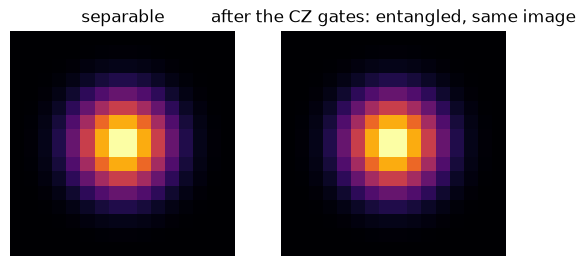

In [4]:
def encode(entangle=True, transform=None, profile="blob"):
    def amplitudes(n_bits):
        if profile == "ramp":
            p = np.arange(2 ** n_bits) + 1.0
            return np.sqrt(p / p.sum())
        return brightness_profile(n_bits)

    qc = QuantumCircuit(N)
    qc.append(StatePreparation(amplitudes(N_ROW)), range(N_ROW))
    qc.append(StatePreparation(amplitudes(N_COL)), range(N_ROW, N))
    qc = transpile(qc, basis_gates=["ry", "rz", "cx", "cz", "h", "x"], optimization_level=1)
    if transform in ("flip_rows", "rotate_180"):
        qc.x(range(N_ROW))
    if transform in ("flip_cols", "rotate_180"):
        qc.x(range(N_ROW, N))
    if entangle:
        qc.cz(0, N_ROW)
        qc.cz(N_ROW - 1, N - 1)
    return qc


def exact_image(qc):
    probabilities = np.abs(qi.Statevector(qc).data) ** 2
    return to_image({"".join(str((i >> q) & 1) for q in range(N)): probabilities[i] for i in range(2 ** N)})


fig = show([exact_image(encode(entangle=False)), exact_image(encode(entangle=True))],
           ["separable", "after the CZ gates: entangled, same image"])
plt.show()

## Cut

For a device of 4 qubits, `find_cut` finds the two CZ gates.

In [5]:
entangled = encode()
cut = qd.find_cut(entangled, max_qubits=N_ROW, gate_cut=True, wire_cut=False)
print(cut, qd.cutting_overhead(entangled, cut))
print(dict(entangled.count_ops()), "depth", entangled.depth())

['CZ_103', 'CZ_104'] {'subcircuits': 72, 'configurations': 36, 'fragments': 2, 'gamma': 9.0}
{'rz': 50, 'ry': 30, 'cx': 22, 'cz': 2} depth 47


## Reconstruct

The three-step form exposes each piece, and each `sample_subcircuit` is a task under PyCOMPSs. The total variation distance (TVD) from the exact image is the sum of the absolute differences over the pixels, divided by 2.

<CutCircuits: 72 subcircuits, 2 fragments, gate ['CZ_103', 'CZ_104'], gamma 9, distribution>


TVD 0.0093


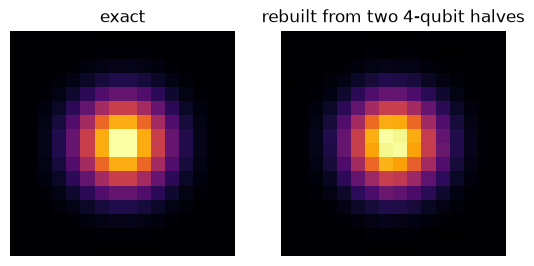

In [6]:
subs = qd.gate_cutting_sampling_subcircuits(entangled, cut)
print(subs)
sampled = [qd.sample_subcircuit(s, shots=50_000, seed=i) for i, s in enumerate(subs)]
reconstructed = to_image(subs.reconstruct(sampled))
exact = exact_image(entangled)
print(f"TVD {0.5 * np.abs(exact - reconstructed).sum():.4f}")
show([exact, reconstructed], ["exact", "rebuilt from two 4-qubit halves"])
plt.show()

Move the slider to see the image at other shot counts.

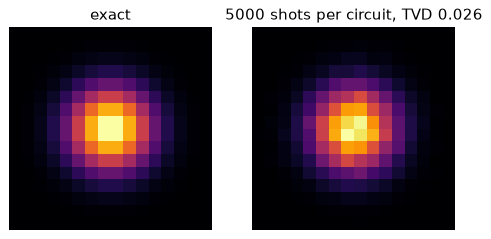

In [7]:
def render(shots):
    image = to_image(qd.gate_cutting_sampling(entangled, cut, shots=shots, seed=1))
    return show([exact, image], ["exact", f"{shots} shots per circuit, TVD {0.5 * np.abs(exact - image).sum():.3f}"])


slider(render, [200, 1000, 5000, 20_000, 100_000], "shots per circuit", start=2)

## A transform that goes through the cut

A mirror reflection is a set of X gates inside one register, so it does not touch the cut. A gradient makes it visible, since a mirrored symmetric blob would look the same.

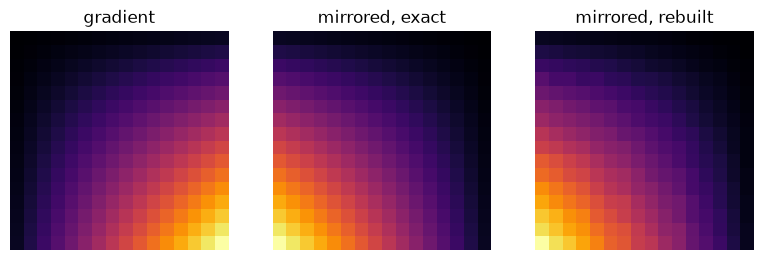

In [8]:
ramp = encode(profile="ramp", transform="flip_cols")
ramp_cut = qd.find_cut(ramp, max_qubits=N_ROW, gate_cut=True, wire_cut=False)
rebuilt = to_image(qd.gate_cutting_sampling(ramp, ramp_cut, shots=50_000, seed=1))
show([exact_image(encode(profile="ramp")), exact_image(ramp), rebuilt],
     ["gradient", "mirrored, exact", "mirrored, rebuilt"])
plt.show()

## With noise

On a device, gate and readout errors blur the image, and the cut's weights amplify shot noise. This is a **simulation** with a depolarizing error on two-qubit gates and on readout, using a backend of the kind in notebook 08. It is not a device result.

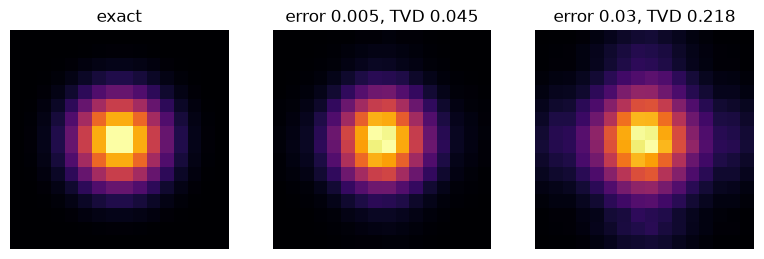

In [9]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError, depolarizing_error


class NoisyAer(qd.BaseBackend):
    def evaluate_samples(self, dag, num_qubits, shots=1024, seed=None):
        error = self.config.extra["error"]
        noise = NoiseModel()
        noise.add_all_qubit_quantum_error(depolarizing_error(error, 2), ["cz", "cx"])
        noise.add_all_qubit_readout_error(ReadoutError([[1 - error, error], [error, 1 - error]]))
        simulator = AerSimulator(noise_model=noise, seed_simulator=seed)
        return qd.sample_with_qiskit(
            dag, num_qubits, lambda qc: simulator.run(qc, shots=shots).result().get_counts()
        )


images, titles = [exact], ["exact"]
for error in (0.005, 0.03):
    device = NoisyAer("NOISY", qd.BackendConfig(num_qubits=20, extra={"error": error}))
    image = to_image(qd.gate_cutting_sampling(entangled, cut, shots=20_000, seed=1, backend=device))
    images.append(image)
    titles.append(f"error {error}, TVD {0.5 * np.abs(exact - image).sum():.3f}")
show(images, titles)
plt.show()

To run the pieces on a BSC QPU, pass `backend="BSC_QPU_BACKEND"`, as in notebook 09. **Not run here:** it needs access to the BSC quantum environment.

```python
distribution = qd.gate_cutting_sampling(entangled, cut, shots=4096, backend="BSC_QPU_BACKEND")
```

To try larger images, change `N_ROW = N_COL = 5` for 32 x 32 at the top: 10 qubits and 5 per half, and still the same two cuts, so the same `gamma`.